In [1]:
import csv
import os
import re
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt

def freq_to_channel(mhz):
    """Convert a centre frequency in MHz to a Wi-Fi channel number."""
    if 2412 <= mhz <= 2472:
        return (mhz - 2407) // 5          # 2.4 GHz: ch 1..13
    if mhz == 2484:
        return 14                          # Japan-only channel 14
    if 5000 <= mhz <= 5900:
        return (mhz - 5000) // 5           # 5 GHz: ch 36, 40, ...
    return None

In [ ]:
def scan_windows():
    """Parse 'netsh wlan show networks mode=bssid' (Windows)."""
    out = subprocess.run(
        ["netsh", "wlan", "show", "networks", "mode=bssid"],
        capture_output=True, text=True).stdout
    nets, ssid = [], None
    for line in out.splitlines():
        line = line.strip()
        m = re.match(r"SSID \d+ : (.*)", line)
        if m:
            ssid = m.group(1).strip() or "<hidden>"
        m = re.match(r"Signal\s*:\s*(\d+)%", line)
        if m and ssid is not None:
            pct = int(m.group(1))
            rssi = pct / 2 - 100          # standard %-to-dBm approximation
            nets.append({"ssid": ssid, "rssi": rssi, "channel": None})
        m = re.match(r"Channel\s*:\s*(\d+)", line)
        if m and nets and nets[-1]["channel"] is None:
            nets[-1]["channel"] = int(m.group(1))
    return [n for n in nets if n["channel"] is not None]

In [3]:
def scan_linux():
    """Parse 'nmcli -t -f SSID,SIGNAL,CHAN dev wifi' (Linux)."""
    out = subprocess.run(
        ["nmcli", "-t", "-f", "SSID,SIGNAL,CHAN", "dev", "wifi"],
        capture_output=True, text=True).stdout
    nets = []
    for line in out.splitlines():
        parts = line.rsplit(":", 2)        # SSID may itself contain ':'
        if len(parts) != 3:
            continue
        ssid, signal, chan = parts
        try:
            pct, ch = int(signal), int(chan)
        except ValueError:
            continue
        nets.append({"ssid": ssid or "<hidden>",
                     "rssi": pct / 2 - 100, "channel": ch})
    return nets

In [4]:
def scan_macos():
    """Parse the macOS 'airport -s' scan output."""
    airport = ("/System/Library/PrivateFrameworks/Apple80211.framework/"
               "Versions/Current/Resources/airport")
    out = subprocess.run([airport, "-s"], capture_output=True, text=True).stdout
    nets = []
    for line in out.splitlines()[1:]:
        m = re.match(r"\s*(.+?)\s+([0-9a-f:]{17})\s+(-\d+)\s+(\d+)", line)
        if m:
            nets.append({"ssid": m.group(1).strip(),
                         "rssi": float(m.group(3)),
                         "channel": int(m.group(4).split(",")[0])})
    return nets

In [5]:
SAMPLE_CSV = """SSID,RSSI_dBm,Channel
MyHomeWiFi,-42,6
Airtel_4G21,-58,1
JioFiber_2G,-61,6
TP-Link_A3F2,-66,6
Neighbour_2G,-70,1
Excitel_204,-72,11
D-Link_Home,-75,4
ACT_Fibernet,-77,9
CoffeeShop_Free,-81,11
MyHomeWiFi_5G,-48,36
JioFiber_5G,-63,44
OnePlus_Hotspot,-69,149
"""
def load_csv(fname="wifi_scan.csv"):
    """Read manually recorded readings (from the phone app) out of a CSV."""
    if not os.path.exists(fname):
        with open(fname, "w") as f:
            f.write(SAMPLE_CSV)
        print(f"[i] No {fname} found - a SAMPLE file was created. Replace its")
        print("    rows with your own readings from the phone app, then rerun.")
    nets = []
    with open(fname) as f:
        for row in csv.DictReader(f):
            nets.append({"ssid": row["SSID"],
                         "rssi": float(row["RSSI_dBm"]),
                         "channel": int(row["Channel"])})
    return nets

In [ ]:
def get_networks():
    """Try a live scan for this OS; fall back to the CSV if it fails."""
    try:
        if sys.platform.startswith("win"):
            nets = scan_windows()
        elif sys.platform == "darwin":
            nets = scan_macos()
        else:
            nets = scan_linux()
        if nets:
            print(f"[i] Live scan found {len(nets)} networks.")
            return nets, "live scan"
    except (FileNotFoundError, OSError):
        pass
    print("[i] Live scan unavailable - using wifi_scan.csv instead.")
    return load_csv(), "wifi_scan.csv"

In [ ]:
def quality(rssi):
    """Map an RSSI reading to the standard signal-quality wording."""
    if rssi >= -50: return "Excellent"
    if rssi >= -60: return "Good"
    if rssi >= -70: return "Fair"
    if rssi >= -80: return "Weak"
    return "Very poor"

def band_of(channel):
    return "2.4 GHz" if channel <= 14 else "5 GHz"
def print_table(nets):
    print(f"\n{'SSID':<20} {'RSSI (dBm)':>10} {'Channel':>8} "
          f"{'Band':>8} {'Quality':>10}")
    print("-" * 62)
    for n in sorted(nets, key=lambda n: n["rssi"], reverse=True):
        print(f"{n['ssid'][:20]:<20} {n['rssi']:>10.0f} {n['channel']:>8} "
              f"{band_of(n['channel']):>8} {quality(n['rssi']):>10}")

def plot_channel_graph(nets, fname="channel_graph_24ghz.png"):
    """
    Draw each 2.4 GHz network as a curve centred on its channel.
    A 20 MHz-wide transmission on channel c occupies roughly channels
    c-2 .. c+2 (channels are only 5 MHz apart), which is why the curves
    overlap - exactly what the phone app shows.    """
    nets24 = [n for n in nets if n["channel"] <= 14]
    fig, ax = plt.subplots(figsize=(10, 5.5))
    cmap = plt.cm.tab10
    floor = -95                            # graph floor (below = unusable)
    for k, n in enumerate(nets24):
        c, r = n["channel"], n["rssi"]
        x = np.linspace(c - 2, c + 2, 200)
        y = floor + (r - floor) * np.cos((x - c) / 2 * np.pi / 2) ** 2
        color = cmap(k % 10)
        ax.plot(x, y, color=color, lw=2)
        ax.fill_between(x, floor, y, color=color, alpha=0.15)
        ax.annotate(n["ssid"], (c, r), textcoords="offset points",
                    xytext=(0, 4), ha="center", fontsize=8, color=color)
    for c in (1, 6, 11):                   # the three non-overlapping channels
        ax.axvline(c, color="gray", ls=":", lw=1)
    ax.set_xticks(range(1, 14))
    ax.set_xlim(-1.5, 15.5)
    ax.set_ylim(floor, -25)
    ax.set_xlabel("2.4 GHz channel number")
    ax.set_ylabel("RSSI (dBm)")
    ax.set_title("Channel graph - each network drawn on its channel "
                 "(dotted lines: non-overlapping channels 1, 6, 11)")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    return fig

[i] Live scan found 3 networks.

=== Wi-Fi survey (live scan) ===

SSID                 RSSI (dBm)  Channel     Band    Quality
--------------------------------------------------------------
Shobhan jhuma kar           -50       11  2.4 GHz  Excellent
TECNO POVA 6 Neo 5G         -95       11  2.4 GHz  Very poor
Shivanshi                   -98       11  2.4 GHz  Very poor

Band summary: 3 networks on 2.4 GHz, 0 on 5 GHz.

Congestion on the three non-overlapping channels:
   channel  1: 0 overlapping network(s)
   channel  6: 0 overlapping network(s)
   channel 11: 3 overlapping network(s)
[>] Recommended channel for a new 2.4 GHz router here: 1

Saved: channel_graph_24ghz.png, channel_congestion.png


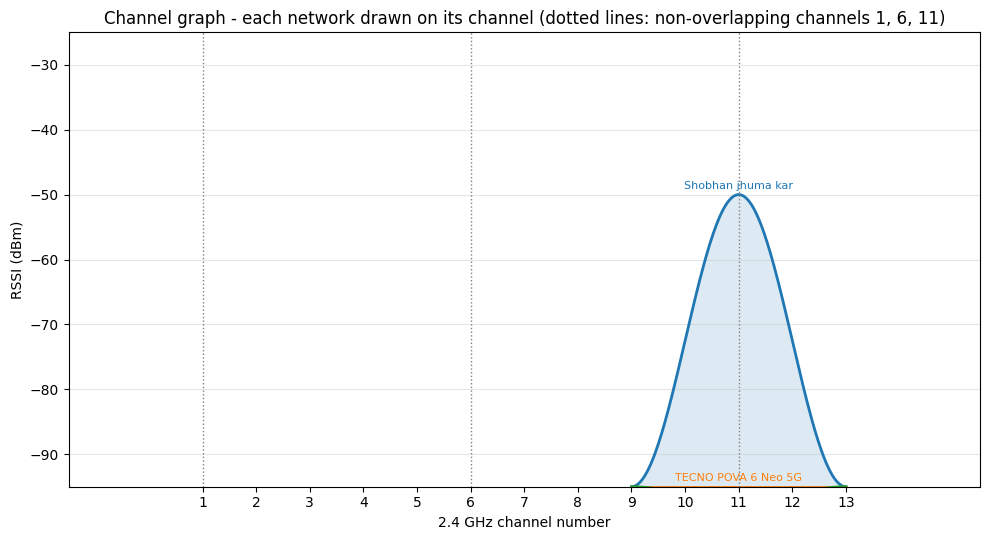

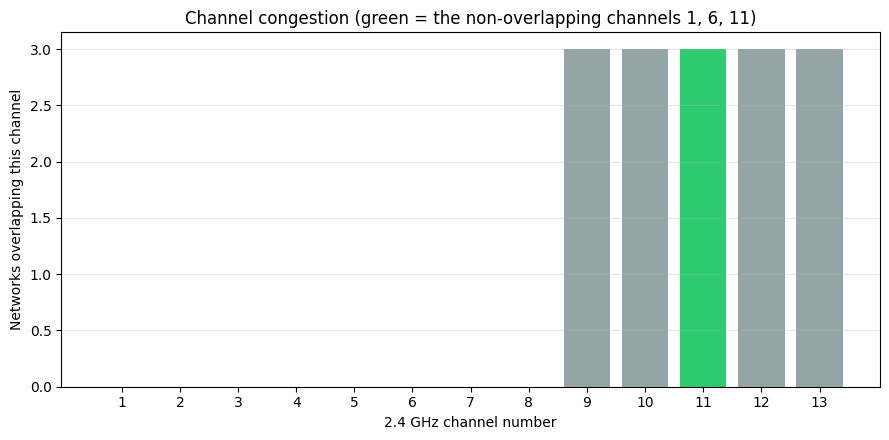

In [ ]:
def congestion(nets):
    """
    Count how many networks OVERLAP each 2.4 GHz channel, not just how many
    are centred on it: a network on channel c interferes with channels
    c-2 .. c+2. This is the number that actually predicts contention.
    """
    counts = {c: 0 for c in range(1, 14)}
    for n in nets:
        if n["channel"] <= 14:
            for c in range(max(1, n["channel"] - 2),
                           min(13, n["channel"] + 2) + 1):
                counts[c] += 1
    return counts

def plot_congestion(nets, fname="channel_congestion.png"):
    counts = congestion(nets)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    colors = ["#2ecc71" if c in (1, 6, 11) else "#95a5a6"
              for c in counts]
    ax.bar(list(counts.keys()), list(counts.values()), color=colors)
    ax.set_xticks(range(1, 14))
    ax.set_xlabel("2.4 GHz channel number")
    ax.set_ylabel("Networks overlapping this channel")
    ax.set_title("Channel congestion (green = the non-overlapping "
                 "channels 1, 6, 11)")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    return fig

def recommend_channel(nets):
    counts = congestion(nets)
    best = min((1, 6, 11), key=lambda c: counts[c])
    print("\nCongestion on the three non-overlapping channels:")
    for c in (1, 6, 11):
        print(f"   channel {c:>2}: {counts[c]} overlapping network(s)")
    print(f"[>] Recommended channel for a new 2.4 GHz router here: {best}")
    return best

if __name__ == "__main__":
    nets, source = get_networks()

    print(f"\n=== Wi-Fi survey ({source}) ===")
    print_table(nets)

    n24 = sum(1 for n in nets if n["channel"] <= 14)
    n5 = len(nets) - n24
    print(f"\nBand summary: {n24} networks on 2.4 GHz, {n5} on 5 GHz.")

    plot_channel_graph(nets)
    plot_congestion(nets)
    recommend_channel(nets)

    print("\nSaved: channel_graph_24ghz.png, channel_congestion.png")
    plt.show()